# LabGuard AI – Engine B: RAG Document Assistant

## Project Overview

This notebook focuses on the development of the Retrieval-Augmented Generation (RAG) component of LabGuard AI.

The objective is to build an intelligent document assistant that helps laboratory personnel retrieve relevant information from quality procedures and investigation records related to the detection of statistically unusual laboratory results.

The RAG pipeline includes the following steps:

1. **Document Loading:** Import Word documents containing laboratory procedures and investigation records.
2. **Text Extraction:** Extract and prepare the document content.
3. **Text Chunking:** Divide documents into smaller text segments.
4. **Embeddings Generation:** Convert text segments into numerical vector representations using a multilingual embedding model.
5. **Vector Indexing:** Store embeddings in a FAISS index for efficient similarity search.
6. **Information Retrieval:** Retrieve relevant document passages based on user questions.
7. **LLM Integration:** Generate answers using the retrieved information, with references to the original documents.
8. **Evaluation:** Assess retrieval relevance, answer accuracy and source traceability.

## Data Sources

The initial knowledge base consists of three project documents:

- `Procedure_anomalies_detection.docx`
- `FICHE-LAB-ANOM-001.docx`
- `FICHE_Cas_Glucose.docx`

## Expected Outcome

The expected result is a prototype of a document assistant capable of answering questions about laboratory anomaly investigation, explaining the steps described in the available procedures and supporting the documentation of identified anomalies.

**Important:** LabGuard AI is designed as a decision-support tool. It does not replace laboratory professionals, biological validation or the laboratory's quality management system.

In [25]:
%pip install sentence-transformers faiss-cpu python-docx pandas openpyxl

Note: you may need to restart the kernel to use updated packages.


In [14]:
pip install faiss-cpu

Note: you may need to restart the kernel to use updated packages.


In [17]:
!pip install langchain-community

In [60]:
%pip install rank-bm25

Note: you may need to restart the kernel to use updated packages.


In [272]:
from pathlib import Path
from docx import Document
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
import faiss
import re
from rank_bm25 import BM25Okapi
from collections import Counter
import importlib.metadata as md
# from rag.generation import generate_answer

In [274]:
file_path = Path(r"C:\Users\amela\P13 Mon projet\FICHE_Cas_Glucose.docx")

print("Fichier existe :", file_path.exists())
print("Format :", file_path.suffix)

Fichier existe : True
Format : .docx


In [276]:
DOCS_PATH = Path(r"C:\Users\amela\P13 Mon projet")

files = {"Procedure": DOCS_PATH / "Procedure_anomalies_detection.docx",
    "Fiche_vierge": DOCS_PATH / "FICHE-LAB-ANOM-001.docx",
    "Cas_Glucose": DOCS_PATH / "FICHE_Cas_Glucose.docx"}

def extract_docx(file_path):
    doc = Document(file_path)
    content = []

    # Conserver l'ordre des paragraphes et des tableaux
    for block in doc.iter_inner_content():

        if hasattr(block, "rows"):
            for row in block.rows:
                text = " | ".join(
                    cell.text.strip() for cell in row.cells
                )
                if text.strip(" |"):
                    content.append(text)

        else:
            text = block.text.strip()
            if text:
                content.append(text)

    return "\n".join(content)

documents = {}

for name, path in files.items():

    if not path.exists():
        print(f"Fichier introuvable : {path}")
        continue

    documents[name] = extract_docx(path)

    print(f"{name} : {len(documents[name])} caractères")

print(f"\nDocuments chargés : {len(documents)}/3")

assert len(documents) == 3, "Tous les documents ne sont pas chargés."

Procedure : 6059 caractères
Fiche_vierge : 2422 caractères
Cas_Glucose : 2871 caractères

Documents chargés : 3/3


In [278]:
print("===== PROCEDURE =====")
print(documents["Procedure"][:1500])

print("\n===== FICHE VIERGE =====")
print(documents["Fiche_vierge"][:500])

print("\n===== CAS GLUCOSE =====")
print(documents["Cas_Glucose"][:500])

===== PROCEDURE =====
PROCÉDURE
Détection, vérification et investigation des résultats biologiques statistiquement atypiques
Référence : PR-LAB-ANOM-001
Version : 0.1 – Projet pilote LabGuard AI
Statut : Projet de procédure – non approuvé pour utilisation en laboratoire
1. Objet
Cette procédure décrit comment détecter, vérifier et examiner les résultats biologiques statistiquement atypiques identifiés par LabGuard AI.
Son objectif est de faciliter l'identification des résultats inhabituels et de permettre au personnel du laboratoire de vérifier leur origine.
2. Domaine d'application
Cette procédure concerne les résultats biologiques numériques analysés par le système LabGuard AI à l'aide de méthodes statistiques et de modèles de Machine Learning, notamment Isolation Forest.
Elle concerne uniquement la détection et l'investigation des résultats atypiques. Elle ne remplace pas les procédures habituelles de validation biologique et de gestion des non-conformités du laboratoire.
3. Définit

##### TEXT CHUNKING

In [281]:
def extract_docx_blocks(file_path):

    doc = Document(file_path)
    blocks = []

    for element in doc.iter_inner_content():

        # Paragraph
        if hasattr(element, "text") and not hasattr(element, "rows"):

            text = element.text.strip()

            if text:
                blocks.append(text)

        # Table
        elif hasattr(element, "rows"):

            table_rows = []

            for row in element.rows:

                row_text = " | ".join(
                    cell.text.strip()
                    for cell in row.cells)

                if row_text.strip(" |"):
                    table_rows.append(row_text)

            if table_rows:
                table_text = "\n".join(table_rows)
                blocks.append("[TABLE]\n" + table_text)

    return blocks

def create_structured_chunks(blocks, max_chars=700):

    chunks = []
    current_chunk = ""

    for block in blocks:

        # Ajouter le bloc si sa taille reste acceptable
        candidate = (
            current_chunk + "\n" + block
            if current_chunk else block)

        if len(candidate) <= max_chars:

            current_chunk = candidate

        else:

            if current_chunk:
                chunks.append(current_chunk)

            # Ne jamais couper un tableau ou un paragraphe
            current_chunk = block

    if current_chunk:
        chunks.append(current_chunk)

    return chunks

### REGENERATE ALL CHUNKS

In [284]:
all_chunks = []

for name, path in files.items():

    blocks = extract_docx_blocks(path)

    chunks = create_structured_chunks(
        blocks,
        max_chars=700)

    for i, chunk in enumerate(chunks):

        all_chunks.append({
            "source": name,
            "chunk_id": i,
            "text": chunk})

    print(f"{name}: {len(chunks)} chunks")

print("\nTotal chunks:", len(all_chunks))

Procedure: 10 chunks
Fiche_vierge: 4 chunks
Cas_Glucose: 5 chunks

Total chunks: 19


In [286]:
for source in files:

    source_chunks = [
        chunk for chunk in all_chunks
        if chunk["source"] == source]

    print("\n" + "=" * 70)
    print("SOURCE:", source)

    for chunk in source_chunks[:3]:

        print(f"\nChunk {chunk['chunk_id']}")
        print("Characters:", len(chunk["text"]))
        print(chunk["text"])


SOURCE: Procedure

Chunk 0
Characters: 567
PROCÉDURE
Détection, vérification et investigation des résultats biologiques statistiquement atypiques
Référence : PR-LAB-ANOM-001
Version : 0.1 – Projet pilote LabGuard AI
Statut : Projet de procédure – non approuvé pour utilisation en laboratoire
1. Objet
Cette procédure décrit comment détecter, vérifier et examiner les résultats biologiques statistiquement atypiques identifiés par LabGuard AI.
Son objectif est de faciliter l'identification des résultats inhabituels et de permettre au personnel du laboratoire de vérifier leur origine.
2. Domaine d'application

Chunk 1
Characters: 643
Cette procédure concerne les résultats biologiques numériques analysés par le système LabGuard AI à l'aide de méthodes statistiques et de modèles de Machine Learning, notamment Isolation Forest.
Elle concerne uniquement la détection et l'investigation des résultats atypiques. Elle ne remplace pas les procédures habituelles de validation biologique et de gestion

In [288]:
print("Total chunks:", len(all_chunks))

for source in files:

    source_chunks = [
        c for c in all_chunks
        if c["source"] == source]

    print(f"\n{source}: {len(source_chunks)} chunks")

# Vérifier les textes vides
empty_chunks = [
    c for c in all_chunks
    if not c["text"].strip()]

print("\nEmpty chunks:", len(empty_chunks))

# Vérifier les doublons exacts
texts = [c["text"] for c in all_chunks]

print("Exact duplicates:", len(texts) - len(set(texts)))

# Vérifier la longueur
print("Longest chunk:", max(len(c["text"]) for c in all_chunks))
print("Shortest chunk:", min(len(c["text"]) for c in all_chunks))

Total chunks: 19

Procedure: 10 chunks

Fiche_vierge: 4 chunks

Cas_Glucose: 5 chunks

Empty chunks: 0
Exact duplicates: 0
Longest chunk: 695
Shortest chunk: 368


### création des embeddings

In [291]:
MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"

embedding_model = SentenceTransformer(MODEL_NAME)

print("Model loaded successfully:", MODEL_NAME)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model loaded successfully: paraphrase-multilingual-MiniLM-L12-v2


### Générer les embeddings

In [294]:
# Extraire les textes
texts = [chunk["text"] for chunk in all_chunks]

# Générer les embeddings
embeddings = embedding_model.encode(
    texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True)

# Convertir au format attendu par FAISS
embeddings = embeddings.astype("float32")

print("Embeddings shape:", embeddings.shape)
print("Data type:", embeddings.dtype)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embeddings shape: (19, 384)
Data type: float32


#### Controler les embeddings

In [297]:
assert len(all_chunks) == embeddings.shape[0]
assert np.isfinite(embeddings).all()

print("Number of chunks:", len(all_chunks))
print("Number of embeddings:", embeddings.shape[0])
print("Vector dimension:", embeddings.shape[1])
print("Missing or infinite values:", np.isnan(embeddings).sum()
      + np.isinf(embeddings).sum())

print("\nEmbedding validation successful.")

Number of chunks: 19
Number of embeddings: 19
Vector dimension: 384
Missing or infinite values: 0

Embedding validation successful.


#### Create FAISS vector index

In [300]:
embedding_dimension = embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(embedding_dimension)

faiss_index.add(embeddings)

print("FAISS index created successfully.")
print("Number of indexed vectors:", faiss_index.ntotal)
print("Vector dimension:", faiss_index.d)

FAISS index created successfully.
Number of indexed vectors: 19
Vector dimension: 384


In [302]:
def search_documents(question, top_k=3):

    # Convert the question into an embedding
    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # Search in FAISS
    k = min(top_k, faiss_index.ntotal)

    scores, indices = faiss_index.search(query_embedding, k)

    results = []

    for score, idx in zip(scores[0], indices[0]):

        if idx == -1:
            continue

        result = metadata[idx].copy()
        result["similarity_score"] = float(score)

        results.append(result)

    return results

In [304]:
metadata = [{
        "source": chunk["source"],
        "chunk_id": chunk["chunk_id"],
        "text": chunk["text"]}
    for chunk in all_chunks]

print("Metadata created successfully.")
print("Number of metadata entries:", len(metadata))

Metadata created successfully.
Number of metadata entries: 19


In [306]:
question = "How should an anomalous laboratory result be investigated?"

results = search_documents(question, top_k=3)

for i, result in enumerate(results, 1):

    print(f"\n--- Result {i} ---")
    print("Source:", result["source"])
    print("Chunk ID:", result["chunk_id"])
    print("Similarity:", round(result["similarity_score"], 4))
    print("Text:")
    print(result["text"])


--- Result 1 ---
Source: Procedure
Chunk ID: 0
Similarity: 0.6991
Text:
PROCÉDURE
Détection, vérification et investigation des résultats biologiques statistiquement atypiques
Référence : PR-LAB-ANOM-001
Version : 0.1 – Projet pilote LabGuard AI
Statut : Projet de procédure – non approuvé pour utilisation en laboratoire
1. Objet
Cette procédure décrit comment détecter, vérifier et examiner les résultats biologiques statistiquement atypiques identifiés par LabGuard AI.
Son objectif est de faciliter l'identification des résultats inhabituels et de permettre au personnel du laboratoire de vérifier leur origine.
2. Domaine d'application

--- Result 2 ---
Source: Procedure
Chunk ID: 5
Similarity: 0.6942
Text:
Toutes les causes ne sont pas nécessairement présentes. L'investigation dépend du cas rencontré.
Étape 4 – Décision
Après vérification, le biologiste ou la personne autorisée décide de la suite à donner.
Les possibilités comprennent :
Aucune anomalie réelle n'est confirmée : l'alerte e

In [308]:
test_questions = [
    "What information should be recorded in the anomaly investigation form?",
    "What happened in the glucose case with Sample ID 23247?",
    "Who is responsible for reviewing and deciding the outcome of an investigation?"
]

for question in test_questions:

    print("\n" + "=" * 80)
    print("QUESTION:", question)
    print("=" * 80)

    results = search_documents(question, top_k=3)

    for i, result in enumerate(results, 1):
        print(f"\nResult {i}")
        print("Source:", result["source"])
        print("Chunk:", result["chunk_id"])
        print("Similarity:", round(result["similarity_score"], 4))
        print(result["text"][:500])


QUESTION: What information should be recorded in the anomaly investigation form?

Result 1
Source: Procedure
Chunk: 7
Similarity: 0.8011
Étape 7 – Enregistrement et traçabilité des anomalies investiguées
Toute anomalie statistique ayant fait l'objet d'une investigation doit être documentée dans une fiche dédiée.
La fiche d'investigation doit contenir au minimum :
La date de détection de l'anomalie.
L'identification de l'examen concerné.
La valeur du résultat et son unité.
La méthode de détection utilisée.
La description de l'anomalie observée.
Les vérifications effectuées.
La cause identifiée ou suspectée.
La décision prise par l

Result 2
Source: Cas_Glucose
Chunk: 3
Similarity: 0.6761
Vérifier une éventuelle erreur de saisie ou de transcription.
Vérifier les informations relatives à l'échantillon.
Examiner les données analytiques disponibles, si elles existent.
Statut de la cause : hypothèse à confirmer.
5. Conclusion de l'investigation
Conclusion provisoire :
Valeur statistiquement

### Implémentation du reranking

In [42]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")

print("CrossEncoder loaded successfully.")

config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

C:\Users\amela\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:137: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\amela\.cache\huggingface\hub\models--cross-encoder--mmarco-mMiniLMv2-L12-H384-v1. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

CrossEncoder loaded successfully.


### Hybrid Search + Reranking

In [50]:
print("hybrid_search:", "hybrid_search" in globals())
print("reranker:", "reranker" in globals())
print("metadata:", "metadata" in globals())
print("faiss_index:", "faiss_index" in globals())

hybrid_search: False
reranker: True
metadata: True
faiss_index: True


In [64]:
# Text tokenizer
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

# Prepare document tokens
tokenized_corpus = [
    tokenize(item["text"])
    for item in metadata]

# Create BM25 index
bm25 = BM25Okapi(tokenized_corpus)

print("BM25 initialized successfully.")
print("Number of documents:", len(tokenized_corpus))

BM25 initialized successfully.
Number of documents: 19


In [66]:
required_objects = [
    "metadata",
    "embedding_model",
    "faiss_index",
    "tokenize",
    "bm25",
    "reranker",
    "hybrid_search",
    "hybrid_rerank_search"]

for name in required_objects:
    print(f"{name}: {'OK' if name in globals() else 'MISSING'}")

metadata: OK
embedding_model: OK
faiss_index: OK
tokenize: OK
bm25: OK
reranker: OK
hybrid_search: OK
hybrid_rerank_search: OK


In [145]:
def faiss_search(question, top_k=3, source_filter=None):

    # 1. Encode the question
    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True).astype("float32")

    # 2. Search all indexed vectors
    scores, indices = faiss_index.search(
        query_embedding,
        faiss_index.ntotal)

    results = []

    # 3. Retrieve documents and apply optional source filter
    for score, idx in zip(scores[0], indices[0]):

        if idx == -1:
            continue

        result = metadata[int(idx)].copy()

        if (source_filter is not None
            and result["source"] not in source_filter):
            continue

        result["similarity_score"] = float(score)
        results.append(result)

        if len(results) == top_k:
            break

    return results

In [147]:
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]

for alpha in alphas:

    correct = 0

    for item in evaluation_data:

        results = hybrid_rerank_search(
            item["question"],
            candidate_k=19,
            top_k=3,
            source_filter=None,
            alpha=alpha
        )

        if any(
            r["source"] == item["expected_source"]
            for r in results
        ):
            correct += 1

    score = correct / len(evaluation_data) * 100

    print(f"Alpha {alpha:.2f} → Hit Rate@3: {score:.2f}%")

Alpha 0.00 → Hit Rate@3: 73.33%
Alpha 0.25 → Hit Rate@3: 73.33%
Alpha 0.50 → Hit Rate@3: 73.33%
Alpha 0.75 → Hit Rate@3: 73.33%
Alpha 1.00 → Hit Rate@3: 73.33%


### Fiche vierge verification

In [311]:
question = "What information should be recorded in the anomaly investigation form?"

results = faiss_search(
    "What information should be recorded in the anomaly investigation form?",
    top_k=3,
    source_filter=["Fiche_vierge"])

for i, result in enumerate(results, 1):
    print(f"\n--- Result {i} ---")
    print("Source:", result["source"])
    print("Chunk:", result["chunk_id"])
    print(result["text"])


--- Result 1 ---
Source: Fiche_vierge
Chunk: 2
Autre cause
Cause non identifiée
Observations :
..............................................................................
..............................................................................
5. Conclusion de l'investigation
Anomalie statistique non confirmée après vérification
Valeur inhabituelle confirmée, sans erreur identifiée
Erreur de données confirmée
Non-conformité identifiée
Investigation complémentaire nécessaire
Cause identifiée ou suspectée :
..............................................................................
6. Actions et décision
[TABLE]
Action décidée | Responsable | Date prévue | Statut
Décision de la personne autorisée :

--- Result 2 ---
Source: Fiche_vierge
Chunk: 1
..............................................................................
3. Vérification initiale
[TABLE]
Point à vérifier | Résultat de la vérification
Identification de l'échantillon | 
Nom de l'examen et unité | 
Valeur enre

In [313]:
question = "What information should be recorded in the anomaly investigation form?"

results = faiss_search("What information should be recorded in the anomaly investigation form?",
    top_k=3,
    source_filter=["Cas_Glucose"])

for i, result in enumerate(results, 1):
    print(f"\n--- Result {i} ---")
    print("Source:", result["source"])
    print("Chunk:", result["chunk_id"])
    print(result["text"])


--- Result 1 ---
Source: Cas_Glucose
Chunk: 3
Vérifier une éventuelle erreur de saisie ou de transcription.
Vérifier les informations relatives à l'échantillon.
Examiner les données analytiques disponibles, si elles existent.
Statut de la cause : hypothèse à confirmer.
5. Conclusion de l'investigation
Conclusion provisoire :
Valeur statistiquement extrêmement atypique, considérée comme une erreur d'enregistrement présumée dans le cadre du projet LabGuard AI.
La confirmation nécessite une vérification de la donnée source par une personne autorisée.
Statut : investigation en attente de confirmation.
6. Actions et décision

--- Result 2 ---
Source: Cas_Glucose
Chunk: 1
Cette valeur est très éloignée de l'intervalle de référence indiqué dans le dataset (70–99 mg/dL).
Dans le cadre de cette étude, cette observation est considérée comme une erreur d'enregistrement présumée, en raison de son caractère extrêmement inhabituel.
Une vérification de la donnée source serait nécessaire pour confirm

In [315]:
question = "What information should be recorded in the anomaly investigation form?"

results = faiss_search("What information should be recorded in the anomaly investigation form?",
    top_k=3,
    source_filter=["Procedure"])

for i, result in enumerate(results, 1):
    print(f"\n--- Result {i} ---")
    print("Source:", result["source"])
    print("Chunk:", result["chunk_id"])
    print(result["text"])


--- Result 1 ---
Source: Procedure
Chunk: 7
Étape 7 – Enregistrement et traçabilité des anomalies investiguées
Toute anomalie statistique ayant fait l'objet d'une investigation doit être documentée dans une fiche dédiée.
La fiche d'investigation doit contenir au minimum :
La date de détection de l'anomalie.
L'identification de l'examen concerné.
La valeur du résultat et son unité.
La méthode de détection utilisée.
La description de l'anomalie observée.
Les vérifications effectuées.
La cause identifiée ou suspectée.
La décision prise par la personne autorisée.
Les actions réalisées, si nécessaire.
L'identification du responsable et la date de clôture.

--- Result 2 ---
Source: Procedure
Chunk: 5
Toutes les causes ne sont pas nécessairement présentes. L'investigation dépend du cas rencontré.
Étape 4 – Décision
Après vérification, le biologiste ou la personne autorisée décide de la suite à donner.
Les possibilités comprennent :
Aucune anomalie réelle n'est confirmée : l'alerte est docume

In [317]:
question = (
    "Who is responsible for reviewing and deciding "
    "the outcome of an investigation?")

results = faiss_search(
    question,
    top_k=5,
    source_filter=None)

for i, result in enumerate(results, 1):

    print(f"\n--- Result {i} ---")
    print("Source:", result["source"])
    print("Chunk:", result["chunk_id"])
    print("Similarity:", round(result["similarity_score"], 4))
    print(result["text"])


--- Result 1 ---
Source: Procedure
Chunk: 4
Similarity: 0.6156
La présence éventuelle d'une erreur de saisie ou de transcription.
La disponibilité des informations nécessaires à l'investigation.
Étape 3 – Investigation
Si l'anomalie nécessite un examen complémentaire, le personnel autorisé recherche les causes possibles :
Pré-analytiques : problème de prélèvement, d'identification, de conservation ou de transport.
Analytiques : problème d'équipement, de réactif, de calibration ou de contrôle qualité.
Post-analytiques : erreur de saisie, de transmission ou de traitement du résultat.
Biologiques : variation biologique possible ou situation nécessitant une interprétation par le biologiste.

--- Result 2 ---
Source: Procedure
Chunk: 2
Similarity: 0.5903
Non-conformité : situation dans laquelle une exigence définie n'est pas respectée.
Investigation : vérification permettant de rechercher l'origine d'une anomalie ou d'un problème.
Important : une anomalie statistique n'est pas automatiquem

In [319]:
test_questions = ["Who is responsible for reviewing and deciding the outcome of an investigation?",
    "What information should be recorded in the anomaly investigation form?",
    "What happened in the glucose case with Sample ID 23247?",
    "How should an anomalous laboratory result be investigated?",
    "Who is responsible for quality follow-up and corrective actions?"]

for question in test_questions:

    print("\n" + "=" * 80)
    print("QUESTION:", question)
    print("=" * 80)

    results = faiss_search(question,top_k=3)

    if not results:
        print("No relevant documents found.")
        continue

    for i, result in enumerate(results, start=1):

        print(f"\n--- Result {i} ---")
        print("Source:", result["source"])
        print("Chunk:", result["chunk_id"])
        print("Similarity:", round(result["similarity_score"], 4))
        print("Text:")
        print(result["text"])


QUESTION: Who is responsible for reviewing and deciding the outcome of an investigation?

--- Result 1 ---
Source: Procedure
Chunk: 4
Similarity: 0.6156
Text:
La présence éventuelle d'une erreur de saisie ou de transcription.
La disponibilité des informations nécessaires à l'investigation.
Étape 3 – Investigation
Si l'anomalie nécessite un examen complémentaire, le personnel autorisé recherche les causes possibles :
Pré-analytiques : problème de prélèvement, d'identification, de conservation ou de transport.
Analytiques : problème d'équipement, de réactif, de calibration ou de contrôle qualité.
Post-analytiques : erreur de saisie, de transmission ou de traitement du résultat.
Biologiques : variation biologique possible ou situation nécessitant une interprétation par le biologiste.

--- Result 2 ---
Source: Procedure
Chunk: 2
Similarity: 0.5903
Text:
Non-conformité : situation dans laquelle une exigence définie n'est pas respectée.
Investigation : vérification permettant de rechercher 

In [321]:
evaluation_data = [

    # =====================================
    # PROCEDURE
    # =====================================

    {"question": "Who is responsible for reviewing and deciding the outcome of an investigation?",
        "expected_source": "Procedure",
        "ground_truth": (
            "The biologist or authorized person reviews the results, "
            "evaluates their significance and decides what action should be taken.")},
    {"question": "What are the responsibilities of laboratory personnel?",
        "expected_source": "Procedure",
        "ground_truth": (
            "Laboratory personnel verify the information related to the "
            "reported result.")},
    {"question": "What are the responsibilities of the quality manager?",
        "expected_source": "Procedure",
        "ground_truth": (
            "The quality manager follows up non-conformities and corrective "
            "actions when necessary.")},
    {"question": "What checks must be performed during the initial verification?",
        "expected_source": "Procedure",
        "ground_truth": (
            "The personnel verify sample identification, test name and unit, "
            "recorded value and its consistency with the available data.")},
    {"question": "What information must be recorded after investigating an anomaly?",
        "expected_source": "Procedure",
        "ground_truth": (
            "The investigation record includes the detection date, test "
            "identification, result and unit, detection method, anomaly "
            "description, checks performed, suspected or identified cause, "
            "decision, actions and closure information.")},

    # =====================================
    # FICHE VIERGE
    # =====================================

    {"question": "What information is required to identify an anomaly alert?",
        "expected_source": "Fiche_vierge",
        "ground_truth": (
            "The form includes investigation number, detection date, Sample ID, "
            "laboratory, biological test, result, unit, reference interval, "
            "dataset outcome and detection method.")},
    {"question": "Which points must be checked during the initial verification?",
        "expected_source": "Fiche_vierge",
        "ground_truth": (
            "Sample identification, test name and unit, recorded value, "
            "reference interval, possible data entry or transcription errors "
            "and available complementary information.")},
    {"question": "Which possible causes of an anomaly should be investigated?",
        "expected_source": "Fiche_vierge",
        "ground_truth": (
            "Possible causes include data entry or transcription errors, "
            "sample identification problems, pre-analytical problems, "
            "analytical problems, post-analytical problems and possible "
            "biological variation.")},
    {"question": "What possible conclusions can be recorded in the investigation form?",
        "expected_source": "Fiche_vierge",
        "ground_truth": (
            "The form allows recording an unconfirmed anomaly, an unusual "
            "value without an identified error, a confirmed data error, "
            "an identified non-conformity or the need for further investigation.")},
    {"question": "What information is recorded in the actions and decision section?",
        "expected_source": "Fiche_vierge",
        "ground_truth": (
            "The form contains the decided action, responsible person, "
            "planned date, status and decision of the authorized person.")},

    # =====================================
    # GLUCOSE CASE
    # =====================================

    {"question": "What glucose result was recorded for Sample ID 23247?",
        "expected_source": "Cas_Glucose",
        "ground_truth": (
            "The recorded glucose result was 10042 mg/dL.")},
    {"question": "What was the reference interval for glucose in Sample ID 23247?",
        "expected_source": "Cas_Glucose",
        "ground_truth": (
            "The reference interval recorded in the dataset was 70-99 mg/dL.")},
    {"question": "What was the main suspected cause of the glucose anomaly?",
        "expected_source": "Cas_Glucose",
        "ground_truth": (
            "A data recording or transcription error was suspected, "
            "but it was not confirmed.")},
    {"question": "What verification is necessary to confirm the suspected glucose recording error?",
        "expected_source": "Cas_Glucose",
        "ground_truth": (
            "The original source data must be checked by an authorized person "
            "to confirm the suspected recording or transcription error.")},
    {"question": "Which anomaly detection method identified the glucose result?",
        "expected_source": "Cas_Glucose",
        "ground_truth": (
            "The anomaly was detected using Isolation Forest.")}]

print("Number of evaluation questions:", len(evaluation_data))

print("Questions per document:",
    dict(Counter(item["expected_source"] for item in evaluation_data)))

Number of evaluation questions: 15
Questions per document: {'Procedure': 5, 'Fiche_vierge': 5, 'Cas_Glucose': 5}


#### Tester les 15 questions sans filtre de document 

In [324]:
retrieval_results = []

for item in evaluation_data:

    results = hybrid_rerank_search(
        item["question"],
        candidate_k=19,
        top_k=3,
        source_filter=None)

    retrieval_results.append({
        "question": item["question"],
        "expected_source": item["expected_source"],
        "ground_truth": item["ground_truth"],
        "results": results})

print("Retrieval evaluation completed.")
print("Number of questions tested:", len(retrieval_results))

Retrieval evaluation completed.
Number of questions tested: 15


In [133]:
correct_source_count = 0

for item in retrieval_results:

    retrieved_sources = [
        result["source"]
        for result in item["results"]]

    if item["expected_source"] in retrieved_sources:
        correct_source_count += 1

source_hit_rate = (correct_source_count / len(retrieval_results)) * 100

print(f"Expected source found in Top 3: {source_hit_rate:.2f}%")

Expected source found in Top 3: 73.33%


In [135]:
diagnostic_results = []

for item in evaluation_data:

    results = hybrid_rerank_search(
        item["question"],
        candidate_k=19,
        top_k=19,
        source_filter=None)

    expected_source = item["expected_source"]

    expected_ranks = [
        rank
        for rank, result in enumerate(results, 1)
        if result["source"] == expected_source]

    first_rank = min(expected_ranks) if expected_ranks else None

    diagnostic_results.append({
        "question": item["question"],
        "expected_source": expected_source,
        "first_expected_rank": first_rank,
        "found_top3": first_rank is not None and first_rank <= 3,
        "found_top5": first_rank is not None and first_rank <= 5,
        "found_top10": first_rank is not None and first_rank <= 10})

diagnostic_df = pd.DataFrame(diagnostic_results)

display(diagnostic_df)

,question,expected_source,first_expected_rank,found_top3,found_top5,found_top10
0,Who is responsible for reviewing and deciding ...,Procedure,1,True,True,True
1,What are the responsibilities of laboratory pe...,Procedure,1,True,True,True
2,What are the responsibilities of the quality m...,Procedure,1,True,True,True
3,What checks must be performed during the initi...,Procedure,2,True,True,True
4,What information must be recorded after invest...,Procedure,1,True,True,True
5,What information is required to identify an an...,Fiche_vierge,6,False,False,True
6,Which points must be checked during the initia...,Fiche_vierge,1,True,True,True
7,Which possible causes of an anomaly should be ...,Fiche_vierge,4,False,True,True
8,What possible conclusions can be recorded in t...,Fiche_vierge,4,False,True,True
9,What information is recorded in the actions an...,Fiche_vierge,4,False,True,True


In [137]:
for k in [1, 3, 5, 10, 19]:

    hit_rate = (
        diagnostic_df["first_expected_rank"].notna()
        & (diagnostic_df["first_expected_rank"] <= k)
    ).mean() * 100

    print(f"Source Hit Rate@{k}: {hit_rate:.2f}%")

Source Hit Rate@1: 60.00%
Source Hit Rate@3: 73.33%
Source Hit Rate@5: 93.33%
Source Hit Rate@10: 100.00%
Source Hit Rate@19: 100.00%


In [139]:
comparison_results = []

for item in evaluation_data:

    question = item["question"]
    expected_source = item["expected_source"]

    # Method 1: FAISS
    faiss_results = search_documents(question, top_k=3)

    # Method 2: Hybrid Search
    hybrid_results = hybrid_search(question, top_k=3)

    # Method 3: Hybrid + CrossEncoder
    rerank_results = hybrid_rerank_search(
        question,
        candidate_k=19,
        top_k=3,
        source_filter=None)

    comparison_results.append({
        "question": question,
        "expected_source": expected_source,
        "FAISS": any(
            r["source"] == expected_source
            for r in faiss_results),
        "Hybrid": any(
            r["source"] == expected_source
            for r in hybrid_results),
        "Hybrid_Rerank": any(
            r["source"] == expected_source
            for r in rerank_results)})

comparison_df = pd.DataFrame(comparison_results)

print("Source Hit Rate@3 comparison:")

for method in ["FAISS", "Hybrid", "Hybrid_Rerank"]:

    score = comparison_df[method].mean() * 100

    print(f"{method}: {score:.2f}%")

Source Hit Rate@3 comparison:
FAISS: 80.00%
Hybrid: 73.33%
Hybrid_Rerank: 73.33%


In [326]:
for item in metadata:

    print("\n" + "=" * 70)
    print("Source:", item["source"])
    print("Chunk:", item["chunk_id"])
    print("-" * 70)
    print(item["text"])


Source: Procedure
Chunk: 0
----------------------------------------------------------------------
PROCÉDURE
Détection, vérification et investigation des résultats biologiques statistiquement atypiques
Référence : PR-LAB-ANOM-001
Version : 0.1 – Projet pilote LabGuard AI
Statut : Projet de procédure – non approuvé pour utilisation en laboratoire
1. Objet
Cette procédure décrit comment détecter, vérifier et examiner les résultats biologiques statistiquement atypiques identifiés par LabGuard AI.
Son objectif est de faciliter l'identification des résultats inhabituels et de permettre au personnel du laboratoire de vérifier leur origine.
2. Domaine d'application

Source: Procedure
Chunk: 1
----------------------------------------------------------------------
Cette procédure concerne les résultats biologiques numériques analysés par le système LabGuard AI à l'aide de méthodes statistiques et de modèles de Machine Learning, notamment Isolation Forest.
Elle concerne uniquement la détection e

In [328]:
relevant_chunks = {

    1: [("Procedure", 2), ("Procedure", 5)],

    2: [("Procedure", 2), ("Procedure", 3), ("Procedure", 4)],

    3: [("Procedure", 2), ("Procedure", 6)],

    # Correction : ajout de Fiche_vierge chunk 1
    4: [
        ("Procedure", 3),
        ("Procedure", 4),
        ("Fiche_vierge", 1)
    ],

    5: [("Procedure", 7), ("Procedure", 8)],

    # Correction : ajout de Procedure chunk 3
    6: [
        ("Fiche_vierge", 0),
        ("Procedure", 3)
    ],

    7: [("Fiche_vierge", 1), ("Procedure", 3), ("Procedure", 4)],

    8: [("Fiche_vierge", 1), ("Fiche_vierge", 2), ("Procedure", 4)],

    9: [("Fiche_vierge", 2)],

    10: [("Fiche_vierge", 2), ("Fiche_vierge", 3)],

    11: [("Cas_Glucose", 0), ("Cas_Glucose", 2)],

    12: [("Cas_Glucose", 0), ("Cas_Glucose", 2)],

    13: [("Cas_Glucose", 1), ("Cas_Glucose", 2), ("Cas_Glucose", 3)],

    14: [("Cas_Glucose", 2), ("Cas_Glucose", 3), ("Cas_Glucose", 4)],

    15: [("Cas_Glucose", 0)]
}

print("Nombre de questions annotées :", len(relevant_chunks))

Nombre de questions annotées : 15


In [330]:
import pandas as pd

k_values = [1, 3, 5]

evaluation_results = []

for question_number, item in enumerate(evaluation_data, start=1):

    question = item["question"]

    # Relevant chunks for this question
    relevant = set(relevant_chunks[question_number])

    for k in k_values:

        # FAISS retrieval
        results = faiss_search(
            question,
            top_k=k
        )

        # Retrieved chunk identifiers
        retrieved = [
            (result["source"], int(result["chunk_id"]))
            for result in results
        ]

        # Relevant chunks retrieved
        relevant_retrieved = [
            chunk for chunk in retrieved
            if chunk in relevant
        ]

        # Hit@k
        hit = int(len(relevant_retrieved) > 0)

        # Precision@k
        precision = len(relevant_retrieved) / k

        # Recall@k
        recall = len(relevant_retrieved) / len(relevant)

        # Reciprocal Rank
        reciprocal_rank = 0

        for rank, chunk in enumerate(retrieved, start=1):
            if chunk in relevant:
                reciprocal_rank = 1 / rank
                break

        evaluation_results.append({
            "Question": question_number,
            "K": k,
            "Hit": hit,
            "Precision": precision,
            "Recall": recall,
            "MRR": reciprocal_rank
        })

# Convert results to DataFrame
results_df = pd.DataFrame(evaluation_results)

# Average metrics for each K
summary = results_df.groupby("K").agg({
    "Hit": "mean",
    "Precision": "mean",
    "Recall": "mean",
    "MRR": "mean"
}).reset_index()

# Convert to percentages
for column in ["Hit", "Precision", "Recall"]:
    summary[column] = summary[column] * 100

print("FAISS RETRIEVAL EVALUATION")
display(summary.round(2))

FAISS RETRIEVAL EVALUATION


,K,Hit,Precision,Recall,MRR
0,1,53.33,53.33,21.11,0.53
1,3,86.67,40.00,54.44,0.69
2,5,86.67,29.33,64.44,0.69


In [332]:
for question_number, item in enumerate(evaluation_data, start=1):

    question = item["question"]

    relevant = set(relevant_chunks[question_number])

    results = faiss_search(
        question,
        top_k=5
    )

    print("\n" + "=" * 90)
    print(f"QUESTION {question_number}: {question}")
    print("=" * 90)

    for rank, result in enumerate(results, start=1):

        chunk_id = (
            result["source"],
            int(result["chunk_id"])
        )

        status = "RELEVANT" if chunk_id in relevant else "NOT RELEVANT"

        print(
            f"Rank {rank} | "
            f"{result['source']} | "
            f"Chunk {result['chunk_id']} | "
            f"Score: {result['similarity_score']:.4f} | "
            f"{status}"
        )


QUESTION 1: Who is responsible for reviewing and deciding the outcome of an investigation?
Rank 1 | Procedure | Chunk 4 | Score: 0.6156 | NOT RELEVANT
Rank 2 | Procedure | Chunk 2 | Score: 0.5903 | RELEVANT
Rank 3 | Procedure | Chunk 7 | Score: 0.5847 | NOT RELEVANT
Rank 4 | Procedure | Chunk 5 | Score: 0.5754 | RELEVANT
Rank 5 | Cas_Glucose | Chunk 3 | Score: 0.5591 | NOT RELEVANT

QUESTION 2: What are the responsibilities of laboratory personnel?
Rank 1 | Procedure | Chunk 9 | Score: 0.4467 | NOT RELEVANT
Rank 2 | Procedure | Chunk 4 | Score: 0.4326 | RELEVANT
Rank 3 | Procedure | Chunk 0 | Score: 0.4231 | NOT RELEVANT
Rank 4 | Procedure | Chunk 3 | Score: 0.4147 | RELEVANT
Rank 5 | Procedure | Chunk 8 | Score: 0.3821 | NOT RELEVANT

QUESTION 3: What are the responsibilities of the quality manager?
Rank 1 | Procedure | Chunk 9 | Score: 0.3258 | NOT RELEVANT
Rank 2 | Procedure | Chunk 6 | Score: 0.2551 | RELEVANT
Rank 3 | Procedure | Chunk 2 | Score: 0.2253 | RELEVANT
Rank 4 | Proced

In [334]:
import importlib.metadata as md

# Check RAGAS installation
try:
    ragas_version = md.version("ragas")
    print("RAGAS version:", ragas_version)
except md.PackageNotFoundError:
    print("RAGAS is not installed.")

# Check evaluation dataset
print("\nNumber of evaluation questions:", len(evaluation_data))

print("\nAvailable fields:")
print(evaluation_data[0].keys())

print("\nFirst evaluation example:")
print("Question:", evaluation_data[0]["question"])
print("Ground truth:", evaluation_data[0]["ground_truth"])

RAGAS version: 0.1.9

Number of evaluation questions: 15

Available fields:
dict_keys(['question', 'expected_source', 'ground_truth'])

First evaluation example:
Question: Who is responsible for reviewing and deciding the outcome of an investigation?
Ground truth: The biologist or authorized person reviews the results, evaluates their significance and decides what action should be taken.


In [336]:
from datasets import Dataset

ragas_data = []

for item in evaluation_data:

    question = item["question"]

    # Retrieve the top 3 chunks using FAISS
    results = faiss_search(
        question,
        top_k=3)

    # Extract retrieved text contexts
    contexts = [
        result["text"]
        for result in results]

    ragas_data.append({
        "question": question,
        "contexts": contexts,
        "ground_truth": item["ground_truth"]})

# Create RAGAS dataset
ragas_dataset = Dataset.from_list(ragas_data)

print(ragas_dataset)

Dataset({
    features: ['question', 'contexts', 'ground_truth'],
    num_rows: 15
})


In [338]:
print("QUESTION:")
print(ragas_dataset[0]["question"])

print("\nGROUND TRUTH:")
print(ragas_dataset[0]["ground_truth"])

print("\nRETRIEVED CONTEXTS:")

for i, context in enumerate(ragas_dataset[0]["contexts"], start=1):
    print(f"\n--- Context {i} ---")
    print(context)

QUESTION:
Who is responsible for reviewing and deciding the outcome of an investigation?

GROUND TRUTH:
The biologist or authorized person reviews the results, evaluates their significance and decides what action should be taken.

RETRIEVED CONTEXTS:

--- Context 1 ---
La présence éventuelle d'une erreur de saisie ou de transcription.
La disponibilité des informations nécessaires à l'investigation.
Étape 3 – Investigation
Si l'anomalie nécessite un examen complémentaire, le personnel autorisé recherche les causes possibles :
Pré-analytiques : problème de prélèvement, d'identification, de conservation ou de transport.
Analytiques : problème d'équipement, de réactif, de calibration ou de contrôle qualité.
Post-analytiques : erreur de saisie, de transmission ou de traitement du résultat.
Biologiques : variation biologique possible ou situation nécessitant une interprétation par le biologiste.

--- Context 2 ---
Non-conformité : situation dans laquelle une exigence définie n'est pas respec

#### RAGAS Mertics

In [341]:
from ragas import evaluate
from ragas.metrics import context_precision, context_recall

print("Context Precision:", context_precision.name)
print("Context Recall:", context_recall.name)

Context Precision: context_precision
Context Recall: context_recall


In [343]:
packages = [
    "ragas",
    "langchain",
    "langchain-core",
    "langchain-mistralai",
    "datasets"]

for package in packages:
    try:
        print(package, ":", md.version(package))
    except md.PackageNotFoundError:
        print(package, ": NOT INSTALLED")

ragas : 0.1.9
langchain : 0.1.20
langchain-core : 0.1.53
langchain-mistralai : 0.1.7
datasets : 5.0.0


In [211]:
%pip uninstall -y langchain-mistralai

Found existing installation: langchain-mistralai 1.1.6
Uninstalling langchain-mistralai-1.1.6:
  Successfully uninstalled langchain-mistralai-1.1.6
Note: you may need to restart the kernel to use updated packages.


In [213]:
%pip install "langchain-mistralai==0.1.7"

Note: you may need to restart the kernel to use updated packages.


In [345]:
print("Requirements of langchain-mistralai:")

for requirement in md.requires("langchain-mistralai") or []:
    if "langchain-core" in requirement.lower():
        print(requirement)

print("\nTesting ChatMistralAI import:")

try:
    from langchain_mistralai import ChatMistralAI
    print("ChatMistralAI import: OK")
except Exception as e:
    print(type(e).__name__, ":", e)

Requirements of langchain-mistralai:
langchain-core (>=0.1.46,<0.3)

Testing ChatMistralAI import:
ChatMistralAI import: OK


In [218]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [347]:
import os
from dotenv import load_dotenv

load_dotenv()

MISTRAL_API_KEY = os.getenv("MISTRAL_API_KEY")

if MISTRAL_API_KEY:
    print("Mistral API key loaded successfully.")
else:
    print("MISTRAL_API_KEY not found.")

Mistral API key loaded successfully.


In [349]:
from langchain_mistralai import ChatMistralAI

mistral_llm = ChatMistralAI(
    model="mistral-small-latest",
    temperature=0,
    max_retries=2
)

print("Mistral evaluator initialized.")

Mistral evaluator initialized.


In [351]:
packages = [
    "ragas",
    "langchain",
    "langchain-core",
    "langchain-mistralai"
]

for package in packages:
    print(package, ":", md.version(package))

ragas : 0.1.9
langchain : 0.1.20
langchain-core : 0.1.53
langchain-mistralai : 0.1.7


In [353]:
from ragas import evaluate
from ragas.metrics import context_precision, context_recall

ragas_results = evaluate(
    dataset=ragas_dataset,
    metrics=[context_precision,context_recall],
    llm=mistral_llm,
    is_async=False)

print(ragas_results)

Evaluating:   0%|          | 0/30 [00:00<?, ?it/s]

{'context_precision': 0.9222, 'context_recall': 0.9667}


In [228]:
ragas_df = ragas_results.to_pandas()

display(ragas_df.round(3))

print("\nGLOBAL RAGAS SCORES")

display(ragas_df[["context_precision", "context_recall"]].mean().to_frame("Mean Score").round(3))

,question,contexts,ground_truth,context_precision,context_recall
0,Who is responsible for reviewing and deciding ...,[La présence éventuelle d'une erreur de saisie...,The biologist or authorized person reviews the...,1.000,1.0
1,What are the responsibilities of laboratory pe...,[Procédure de gestion des non-conformités du l...,Laboratory personnel verify the information re...,0.833,1.0
2,What are the responsibilities of the quality m...,[Procédure de gestion des non-conformités du l...,The quality manager follows up non-conformitie...,1.000,1.0
3,What checks must be performed during the initi...,[................................................,"The personnel verify sample identification, te...",0.833,1.0
4,What information must be recorded after invest...,[Étape 7 – Enregistrement et traçabilité des a...,The investigation record includes the detectio...,0.833,1.0
5,What information is required to identify an an...,[Étape 7 – Enregistrement et traçabilité des a...,"The form includes investigation number, detect...",0.833,0.5
6,Which points must be checked during the initia...,[................................................,"Sample identification, test name and unit, rec...",1.000,1.0
7,Which possible causes of an anomaly should be ...,[La présence éventuelle d'une erreur de saisie...,Possible causes include data entry or transcri...,1.000,1.0
8,What possible conclusions can be recorded in t...,[Vérifier une éventuelle erreur de saisie ou d...,The form allows recording an unconfirmed anoma...,1.000,1.0
9,What information is recorded in the actions an...,[Étape 7 – Enregistrement et traçabilité des a...,"The form contains the decided action, responsi...",0.833,1.0



GLOBAL RAGAS SCORES


,Mean Score
context_precision,0.911
context_recall,0.967


### Construire le prompt de génération

In [356]:
def generate_rag_answer(question, contexts):

    context_text = "\n\n".join(contexts)

    prompt = f"""
You are LabGuard AI, a laboratory quality document assistant.

Answer the question using ONLY the information in the retrieved documents.

Rules:
- Do not invent information.
- Do not use external knowledge.
- If the documents do not contain enough information,
  clearly say that the information is not available.
- Distinguish a suspected cause from a confirmed cause.
- Do not make clinical decisions.
- Answer in the same language as the question.
- Be clear and concise.

QUESTION:
{question}

RETRIEVED DOCUMENTS:
{context_text}

ANSWER:
"""

    response = mistral_llm.invoke(prompt)

    return response.content

In [358]:
phase2_data = []

for item in evaluation_data:

    question = item["question"]

    # Retrieve top 3 chunks
    retrieved = faiss_search(
        question,
        top_k=3)

    # Preserve document provenance
    contexts = [
        f"[Source: {r['source']} | Chunk: {r['chunk_id']}]\n{r['text']}"
        for r in retrieved]

    # Generate answer with Mistral
    answer = generate_rag_answer(
        question,
        contexts)

    phase2_data.append({
        "question": question,
        "contexts": contexts,
        "answer": answer,
        "ground_truth": item["ground_truth"]})

print("Number of generated answers:", len(phase2_data))

Number of generated answers: 15


In [360]:
for i, item in enumerate(phase2_data, start=1):

    print("\n" + "=" * 80)
    print("QUESTION", i)
    print(item["question"])

    print("\nGENERATED ANSWER:")
    print(item["answer"])

    print("\nGROUND TRUTH:")
    print(item["ground_truth"])


QUESTION 1
Who is responsible for reviewing and deciding the outcome of an investigation?

GENERATED ANSWER:
D'après les documents, c'est le **Biologiste ou la personne autorisée** qui est responsable de **réviser les résultats, évaluer leur signification et décider des suites à donner** (y compris l'issue de l'investigation).

La décision prise par cette personne doit être **documentée** dans la fiche d'investigation.

GROUND TRUTH:
The biologist or authorized person reviews the results, evaluates their significance and decides what action should be taken.

QUESTION 2
What are the responsibilities of laboratory personnel?

GENERATED ANSWER:
D'après les documents fournis, les responsabilités du personnel de laboratoire incluent :

1. **Détection et vérification des résultats atypiques** :
   - Identifier et examiner les résultats biologiques statistiquement inhabituels (Source : *PR-LAB-ANOM-001*).

2. **Investigation des non-conformités** :
   - Rechercher les causes possibles des an

### Préparer les embeddings pour RAGAS evaluation Faithfullnes et Answer Relevancy et Answer Correctness les embeddings

In [363]:
from langchain_core.embeddings import Embeddings

class LocalSentenceTransformerEmbeddings(Embeddings):

    def embed_documents(self, texts):

        vectors = embedding_model.encode(
            texts,
            convert_to_numpy=True,
            normalize_embeddings=True)

        return vectors.tolist()

    def embed_query(self, text):

        vector = embedding_model.encode(
            [text],
            convert_to_numpy=True,
            normalize_embeddings=True)[0]

        return vector.tolist()


local_embeddings = LocalSentenceTransformerEmbeddings()

print("Local embeddings initialized.")

Local embeddings initialized.


In [365]:
from datasets import Dataset

generation_dataset = Dataset.from_list(phase2_data)

print(generation_dataset)

Dataset({
    features: ['question', 'contexts', 'answer', 'ground_truth'],
    num_rows: 15
})


In [367]:
test_response = mistral_llm.invoke(
    "Réponds simplement : LabGuard AI fonctionne.")

print(test_response.content)

**LabGuard AI fonctionne.** ✅


In [369]:
from ragas import evaluate
from ragas.metrics import (
    faithfulness,
    answer_relevancy,
    answer_correctness)

generation_results = evaluate(
    dataset=generation_dataset,
    metrics=[
        faithfulness,
        answer_relevancy,
        answer_correctness],
    llm=mistral_llm,
    embeddings=local_embeddings,
    is_async=False)

generation_df = generation_results.to_pandas()

display(generation_df.round(3))

Evaluating:   0%|          | 0/45 [00:00<?, ?it/s]

,question,contexts,answer,ground_truth,faithfulness,answer_relevancy,answer_correctness
0,Who is responsible for reviewing and deciding ...,[[Source: Procedure | Chunk: 4]\nLa présence é...,"D'après les documents, c'est le **Biologiste o...",The biologist or authorized person reviews the...,1.000,0.858,0.755
1,What are the responsibilities of laboratory pe...,[[Source: Procedure | Chunk: 9]\nProcédure de ...,"D'après les documents fournis, les responsabil...",Laboratory personnel verify the information re...,0.923,0.926,0.157
2,What are the responsibilities of the quality m...,[[Source: Procedure | Chunk: 9]\nProcédure de ...,"D'après les documents disponibles, les respons...",The quality manager follows up non-conformitie...,1.000,0.670,0.918
3,What checks must be performed during the initi...,[[Source: Fiche_vierge | Chunk: 1]\n.............,Les vérifications à effectuer lors de la **vér...,"The personnel verify sample identification, te...",1.000,0.892,0.575
4,What information must be recorded after invest...,[[Source: Procedure | Chunk: 7]\nÉtape 7 – Enr...,Voici les informations qui doivent être enregi...,The investigation record includes the detectio...,1.000,0.936,0.164
5,What information is required to identify an an...,[[Source: Procedure | Chunk: 7]\nÉtape 7 – Enr...,"Pour identifier une alerte d'anomalie, les inf...","The form includes investigation number, detect...",1.000,0.783,0.394
6,Which points must be checked during the initia...,[[Source: Fiche_vierge | Chunk: 1]\n.............,Voici les points à vérifier lors de la **vérif...,"Sample identification, test name and unit, rec...",1.000,0.877,0.828
7,Which possible causes of an anomaly should be ...,[[Source: Procedure | Chunk: 4]\nLa présence é...,Les causes possibles d'une anomalie à investig...,Possible causes include data entry or transcri...,1.000,0.889,0.613
8,What possible conclusions can be recorded in t...,[[Source: Cas_Glucose | Chunk: 3]\nVérifier un...,Voici les conclusions possibles à enregistrer ...,The form allows recording an unconfirmed anoma...,0.200,0.928,0.516
9,What information is recorded in the actions an...,[[Source: Procedure | Chunk: 7]\nÉtape 7 – Enr...,"D'après les documents fournis, les information...","The form contains the decided action, responsi...",1.000,0.868,0.345


In [371]:
generation_metrics = [
    "faithfulness",
    "answer_relevancy",
    "answer_correctness"]

print("GLOBAL GENERATION SCORES")

display(generation_df[generation_metrics]
    .mean()
    .to_frame("Mean Score")
    .round(3))

GLOBAL GENERATION SCORES


,Mean Score
faithfulness,0.942
answer_relevancy,0.819
answer_correctness,0.609


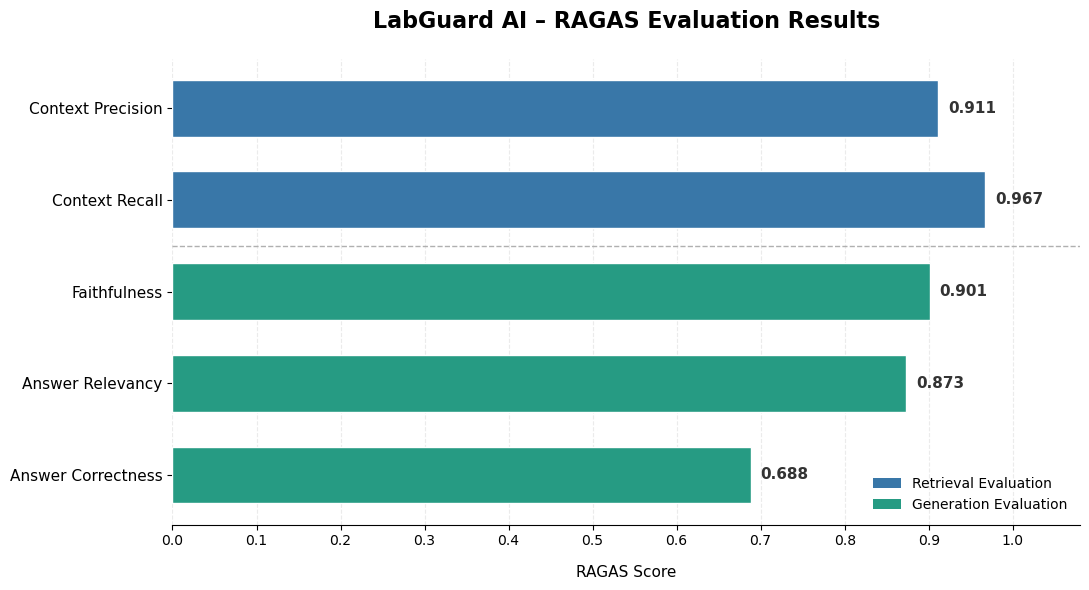

In [373]:

import matplotlib.pyplot as plt
import numpy as np

# Scores RAGAS
retrieval_scores = {
    "Context Precision": 0.911,
    "Context Recall": 0.967
}

generation_scores = {
    "Faithfulness": 0.901,
    "Answer Relevancy": 0.873,
    "Answer Correctness": 0.688
}

# Préparation des données
metrics = list(retrieval_scores.keys()) + list(generation_scores.keys())
scores = list(retrieval_scores.values()) + list(generation_scores.values())

# Deux couleurs pour distinguer les phases
colors = ["#3977A8"] * len(retrieval_scores) + ["#269B83"] * len(generation_scores)

# Création du graphique
fig, ax = plt.subplots(figsize=(11, 6))

y_pos = np.arange(len(metrics))

bars = ax.barh(
    y_pos,
    scores,
    color=colors,
    height=0.62,
    edgecolor="white"
)

# Valeurs affichées sur les barres
for bar, score in zip(bars, scores):
    ax.text(
        score + 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.3f}",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#333333"
    )

# Axes et labels
ax.set_yticks(y_pos)
ax.set_yticklabels(metrics, fontsize=11)
ax.set_xlim(0, 1.08)
ax.set_xlabel("RAGAS Score", fontsize=11, labelpad=12)

ax.set_title(
    "LabGuard AI – RAGAS Evaluation Results",
    fontsize=16,
    fontweight="bold",
    pad=22
)

# Séparation visuelle entre Retrieval et Generation
ax.axhline(
    y=1.5,
    color="#B0B0B0",
    linestyle="--",
    linewidth=1
)

# Légende
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="#3977A8", label="Retrieval Evaluation"),
    Patch(facecolor="#269B83", label="Generation Evaluation")
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=False,
    fontsize=10
)

# Présentation
ax.invert_yaxis()
ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

# Suppression des bordures inutiles
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()

# Export haute résolution
plt.savefig(
    "LabGuard_AI_RAGAS_Results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


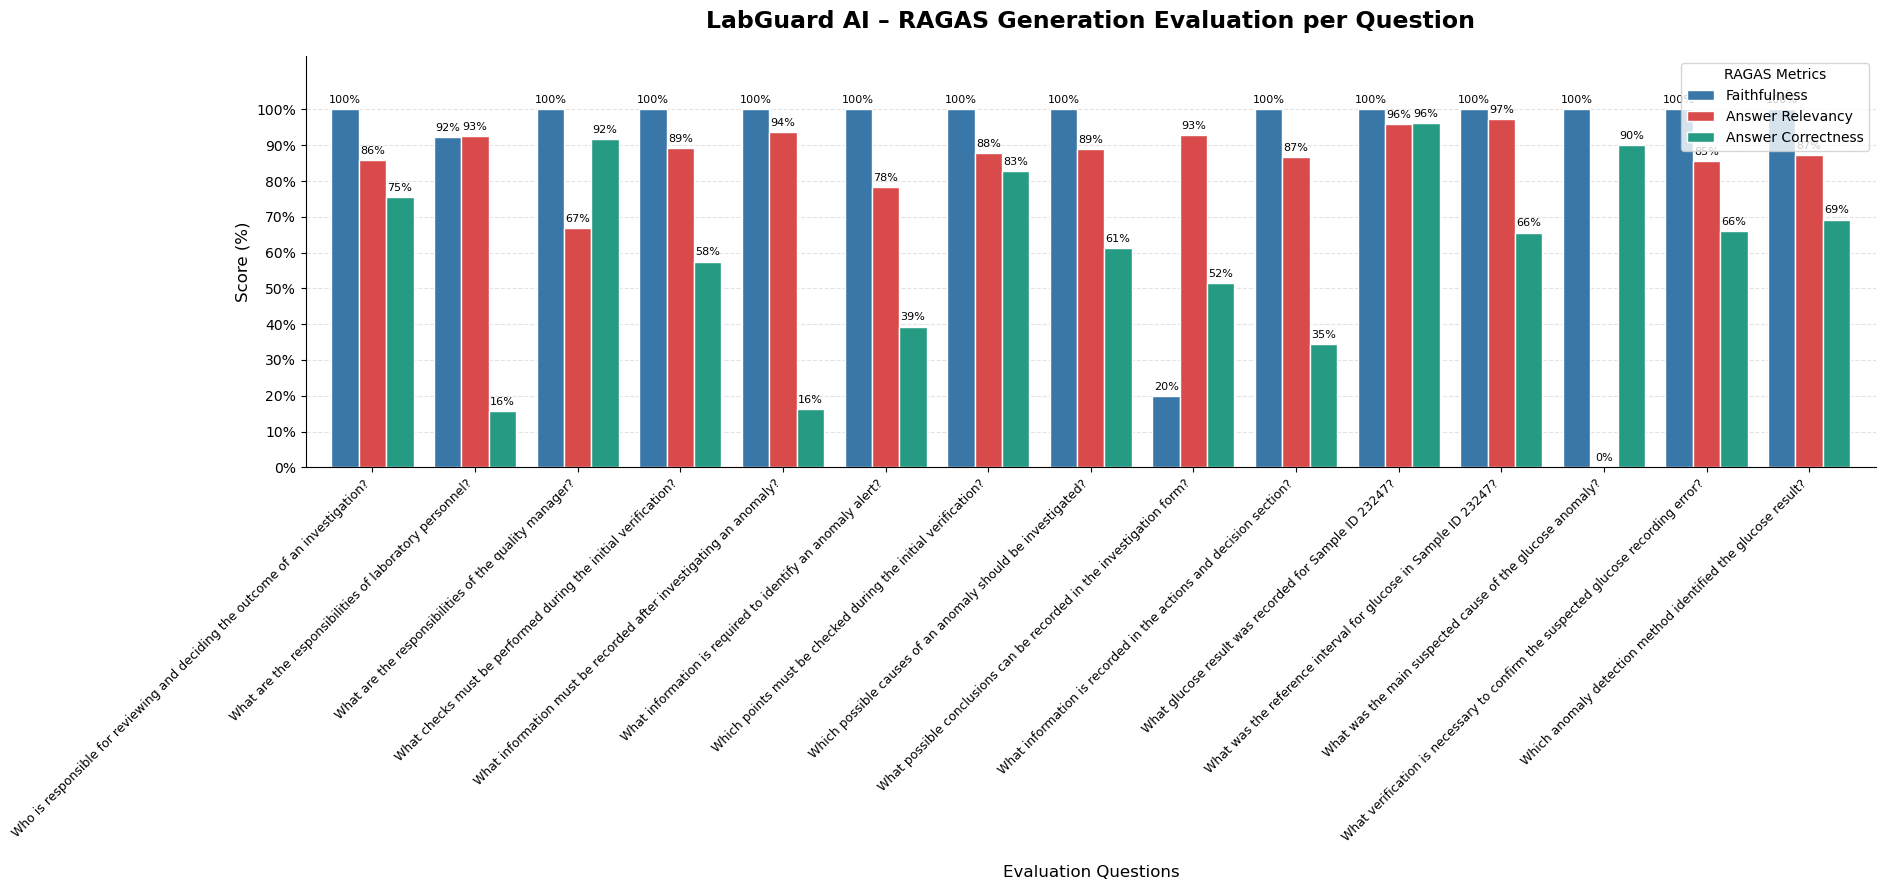

In [375]:
# 1. Sélection des métriques
metrics = [
    "faithfulness",
    "answer_relevancy",
    "answer_correctness"]

# 2. Préparation des données en pourcentage
df_plot = generation_df[metrics].copy() * 100

# 3. Récupération des questions depuis evaluation_data
questions = [
    item["question"] for item in evaluation_data]

df_plot.index = questions

# 4. Création du graphique
fig, ax = plt.subplots(figsize=(19, 9))

colors = ["#3977A8", "#D94B4B", "#269B83"]

df_plot.plot(
    kind="bar",
    ax=ax,
    width=0.8,
    color=colors,
    edgecolor="white")

# 5. Titre et axes
ax.set_title(
    "LabGuard AI – RAGAS Generation Evaluation per Question",
    fontsize=17,
    fontweight="bold",
    pad=20)

ax.set_xlabel("Evaluation Questions", fontsize=12, labelpad=15)
ax.set_ylabel("Score (%)", fontsize=12)

ax.set_ylim(0, 115)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_yticklabels([f"{i}%" for i in range(0, 101, 10)])

# 6. Affichage des scores sur les barres
for container in ax.containers:
    labels = [
        f"{bar.get_height():.0f}%"
        for bar in container]

    ax.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=8)

# 7. Légende
ax.legend(
    ["Faithfulness", "Answer Relevancy", "Answer Correctness"],
    title="RAGAS Metrics",
    loc="upper right",
    frameon=True,
    fontsize=10)

# 8. Questions en diagonale
plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9)

# 9. Grille et esthétique
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# 10. Ajustement et export
plt.tight_layout()

plt.savefig(
    "LabGuard_AI_Generation_Per_Question.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

In [381]:
from pathlib import Path
import pickle
import faiss

# Dossier de sauvegarde du RAG
RAG_PATH = Path("rag")
RAG_PATH.mkdir(exist_ok=True)

# Sauvegarder FAISS
faiss.write_index(
    faiss_index,
    str(RAG_PATH / "faiss_index.bin")
)

# Sauvegarder les métadonnées
with open(RAG_PATH / "metadata.pkl", "wb") as f:
    pickle.dump(metadata, f)

print("FAISS index and metadata saved successfully.")
print("Number of vectors:", faiss_index.ntotal)
print("Number of metadata entries:", len(metadata))

FAISS index and metadata saved successfully.
Number of vectors: 19
Number of metadata entries: 19


In [390]:
import pickle
from pathlib import Path

with open("rag/metadata.pkl", "rb") as f:
    metadata = pickle.load(f)

print("Nombre total de chunks :", len(metadata))

print("\nSources enregistrées :")

sources = set(item.get("source") for item in metadata)

for source in sorted(sources):
    print(repr(source))

Nombre total de chunks : 19

Sources enregistrées :
'Cas_Glucose'
'Fiche_vierge'
'Procedure'


In [392]:
for item in metadata:

    source = str(item.get("source", ""))

    if "glucose" in source.lower():

        print("\nSource :", repr(source))
        print("Chunk ID :", item.get("chunk_id"))
        print("Texte :", item.get("text")[:200])


Source : 'Cas_Glucose'
Chunk ID : 0
Texte : CAS D'ÉTUDE GLUCOSE
CAS D'ÉTUDE – DONNÉES DU DATASET
1. Identification de l'alerte
[TABLE]
Information | Donnée
Numéro de l'investigation | LAB-ANOM-0001
Date de détection | 2026-11-11
Sample ID | 232

Source : 'Cas_Glucose'
Chunk ID : 1
Texte : Cette valeur est très éloignée de l'intervalle de référence indiqué dans le dataset (70–99 mg/dL).
Dans le cadre de cette étude, cette observation est considérée comme une erreur d'enregistrement prés

Source : 'Cas_Glucose'
Chunk ID : 2
Texte : [TABLE]
Point à vérifier | Résultat
Identification de l'échantillon | Sample ID 23247 disponible dans le dataset
Nom de l'examen | Glucose
Unité | mg/dL
Valeur enregistrée | 10 042 mg/dL
Intervalle de

Source : 'Cas_Glucose'
Chunk ID : 3
Texte : Vérifier une éventuelle erreur de saisie ou de transcription.
Vérifier les informations relatives à l'échantillon.
Examiner les données analytiques disponibles, si elles existent.
Statut de la cause :

Source : 'Cas_G

In [394]:
print(repr(sources))

{'Fiche_vierge', 'Procedure', 'Cas_Glucose'}
